# Stage 6 — Diverse Stress-Scenario Discovery and Validation

## 1. Objective, inputs and plan
**Question.** Can we build a library of *distinct, plausible, robust* stress scenarios that expose different portfolio vulnerabilities, rather than many variants of one market-wide decline? The library is written in a structured form for a future Stage 7 recommendation system (Stage 7 is not started here). *Re-run 2026-10-25:* library schema v2 stores the full five-day path used for robustness (v1 stored only the deterministically executed days; v1 library and notebook kept in `backups/`).

**What Stage 5 leaves behind (inspected).** `stage_5.ipynb` stores display tables only; trained Q-tables, candidate sequences and Monte Carlo pools are not saved anywhere. Stage 6 therefore **regenerates candidates with the existing, unchanged implementations** (`rlstress.search`, same seeds and budgets as Stage 5), so the Stage 5 numbers are reproduced rather than assumed (checked in Part 13).

**Methods and candidate sources** (provenance kept for every candidate):
| Source | Kind | Note |
|---|---|---|
| Monte Carlo (original) | random continuous paths, deterministic evaluation | 6,000, seed 44 (Stage 5 Part 6) |
| Monte Carlo (discrete) | random nine-action sequences, scored on 10 sampled draws | step budget = Q-learning β = 0 seed 43 (Stage 5 Part 11) |
| Q-learning β = 0 / β = 5 | deterministic greedy path per training seed | seeds 43, 44, 45, 20,000 episodes each |
| Q-learning β = 0 / β = 5 | adaptive-policy trajectories **replayed as fixed sequences** | from separate discovery episodes (training anchors, seeds 70,000…); the transformation is recorded |
| Scripted decline | manual reference benchmark | never counted as a discovery |

**Pipeline.** candidates → exact duplicates → execution-equivalent duplicates (identical executed days) → deterministic validity (existing rule, q = 0.01) → families → near-duplicate groups (cut = one action step) → scenario clusters (cut = two steps, with sensitivity) → representatives → robustness on fresh residual draws → portfolio vulnerability → library.

**Declared selection rule (fixed before running).** A cluster representative is **validated** iff it is a deterministic valid breach (rank ≥ q) **and** its valid-breach share on the 200 *screening* episodes (validation anchors, seeds `selection_seed`…) is ≥ 80%. Reported probabilities come from the separate 500 *reporting* episodes (seeds `eval_seed_sets[0]`…) with 95% Wilson intervals. Every other representative is kept as **exploratory**.

**Compute (full mode, measured Stage 5 speeds, one core).** Q-learning 6 × ~3.2 min ≈ 19 min; Monte Carlo original ≈ 1 min; discrete Monte Carlo ≈ 3 min; candidate evaluation and trajectory harvesting ≈ 2 min; robustness ≈ 8 s per representative (700 episodes); total about 30–35 min. No PPO, no CEM, no exhaustive search; the 2024–2025 test split is never used.

## 2. Imports, configuration, and reproducibility

In [1]:
import dataclasses
import json
import time
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import PercentFormatter

from rlstress.config import PROJECT_ROOT, load_config, resolve_path
from rlstress.data.storage import read_frame
from rlstress.rl.evaluation import evaluate_policy
from rlstress.rl.training import build_env
from rlstress.scenario_library import (FACTOR_ORDER, LIBRARY_SCHEMA_VERSION, UNCLASSIFIED, candidate_id, classify_family,
                                       cluster_features, cluster_sensitivity, cumulative_feature, execution_key, factor_attribution,
                                       factor_shock_path, holding_contributions, one_step_distance, robustness_summary, scenario_id,
                                       sequence_key, to_json, validate_library)
from rlstress.search import (GroupedActions, OpenLoopPolicy, QConfig, QGreedyPolicy, StateEncoder, evaluate_path, monte_carlo,
                             monte_carlo_sequences, train_q_learning)
from rlstress.shocks import ShockModel, fit_shock_model

%matplotlib inline
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e4e3dc", "grid.linewidth": 0.8})

CFG = load_config()
SIM, ENVC, TRN = CFG.simulation, CFG.environment, CFG.training
Q_THRESHOLD = SIM.min_plausibility                     # q = 0.01, unchanged
H, K = SIM.horizon_days, len(SIM.factors)
SEED = SIM.seed
RETURNS_PATH = resolve_path(CFG.risk.returns_path, PROJECT_ROOT)
STAGE4_MODEL = PROJECT_ROOT / SIM.output_dir / "shock_model.json"
OUT_DIR = PROJECT_ROOT / "results" / "stage6"
LIBRARY_PATH = OUT_DIR / "scenario_library.json"
OVERWRITE = False                                      # never replace an existing library silently

RUN_MODE = "full"    # "smoke": tiny mechanics check (writes nothing). "full": the Stage 6 experiment (writes the library).
SETTINGS = {
    "smoke": dict(mc_budget=120, q_episodes=200, mcd_draws=4, harvest_episodes=10, screening_episodes=20, report_episodes=40, mcd_budget=400),
    "full":  dict(mc_budget=6000, q_episodes=20_000, mcd_draws=10, harvest_episodes=200, screening_episodes=TRN.selection_episodes,
                  report_episodes=TRN.validation_episodes, mcd_budget=None),     # None: budget = steps of Q-learning beta=0 seed 43
}[RUN_MODE]
BETAS, Q_SEEDS = (0.0, 5.0), (SEED + 1, SEED + 2, SEED + 3)
P_VALID_TARGET = 0.80
DELTA = 0.10                                          # family materiality (normalised action units)
SCREEN_SEEDS = range(TRN.selection_seed, TRN.selection_seed + SETTINGS["screening_episodes"])        # validation anchors, selection only
REPORT_SEEDS = range(TRN.eval_seed_sets[0], TRN.eval_seed_sets[0] + SETTINGS["report_episodes"])      # validation anchors, reporting only
HARVEST_SEED, MCD_DRAW_SEED, MCD_SEED = 70_000, 50_000, SEED + 4                                       # training anchors
STAGE5_RECORDED = {"mc_original_breaches": 2027, "mc_original_valid": 0, "q_beta0_seed43_steps": 79_738, "q_beta5_seed43_steps": 88_102}
BANNER = "SMOKE TEST (tiny budget) — results NOT YET EVALUATED, nothing written" if RUN_MODE == "smoke" else "FULL RUN — Stage 6"

assert RETURNS_PATH.exists() and STAGE4_MODEL.exists()
assert not set(SCREEN_SEEDS) & set(REPORT_SEEDS)
print(f"RUN_MODE = {RUN_MODE}: {BANNER}\nSettings: {SETTINGS}")

RUN_MODE = full: FULL RUN — Stage 6
Settings: {'mc_budget': 6000, 'q_episodes': 20000, 'mcd_draws': 10, 'harvest_episodes': 200, 'screening_episodes': 200, 'report_episodes': 500, 'mcd_budget': None}


## 3. Stage 4 environment, factor mapping and data protocol

In [2]:
source = read_frame(RETURNS_PATH)
model = ShockModel.from_dict(json.loads(STAGE4_MODEL.read_text()))
train_start, train_end = CFG.data.splits.as_dict()["train"]
refit = fit_shock_model(source, CFG.portfolio.tickers, SIM, train_start, train_end, CFG.portfolio.return_column_template)
assert np.array_equal(refit.sigma, model.sigma) and refit.path_calibration == model.path_calibration, "saved model != training refit"
assert tuple(model.factors) == FACTOR_ORDER, f"factor order {model.factors}"

cfg_mean = dataclasses.replace(CFG, simulation=dataclasses.replace(SIM, residual_mode="mean"))
search_env = build_env(cfg_mean, source, model, Q_THRESHOLD, "train")         # deterministic, training anchors
train_env = build_env(CFG, source, model, Q_THRESHOLD, "train")               # sampled residuals, training anchors
eval_env = build_env(CFG, source, model, Q_THRESHOLD, "validation")           # sampled residuals, validation anchors
SEARCH_ANCHOR = search_env.market_states.index[len(search_env.market_states) // 2]
OBS = {n: i for i, n in enumerate(search_env.observation_names)}
BOUNDS = search_env.simulator.bounds
unit_in_sd = BOUNDS / model.factor_sd
assert np.allclose(unit_in_sd, unit_in_sd[0]), "action units not comparable across factors"
evaluate = lambda x: evaluate_path(search_env, x, SEARCH_ANCHOR, SEED)
names = [f.removesuffix("_return") for f in FACTOR_ORDER]
TICKERS, WEIGHTS = search_env.portfolio.tickers, search_env.portfolio.weight_vector()
display(pd.DataFrame({"factor": names, "bound |a| = 1 (daily return)": BOUNDS, "model sd": model.factor_sd, "one action unit in sd": unit_in_sd})
        .style.hide(axis="index").format({"bound |a| = 1 (daily return)": "{:.2%}", "model sd": "{:.3%}", "one action unit in sd": "{:.1f}"}))
splits = CFG.data.splits.as_dict()
print(f"Training anchors {search_env.market_states.index.min().date()} -> {search_env.market_states.index.max().date()}; "
      f"validation anchors {eval_env.market_states.index.min().date()} -> {eval_env.market_states.index.max().date()}; test split {splits['test']} unused.")

factor,bound |a| = 1 (daily return),model sd,one action unit in sd
SPY,12.67%,1.056%,12.0
QQQ,15.96%,1.330%,12.0
XLF,16.92%,1.410%,12.0
XLE,23.36%,1.946%,12.0


Training anchors 2015-01-27 -> 2021-12-31; validation anchors 2022-01-03 -> 2023-12-29; test split ('2024-01-01', '2025-12-31') unused.


## 4. Candidate generation with the existing implementations

In [3]:
ACTS = GroupedActions(abs(TRN.scripted_action), k=K)
ENC = StateEncoder(OBS, H, dd_edges=[0.02, 0.04, 0.06, 0.08, 0.10], rank_edges=[Q_THRESHOLD, 0.05, 0.20])
timing = {}

t0 = time.perf_counter()
mc = monte_carlo(evaluate, H * K, SETTINGS["mc_budget"], seed=SEED + 2)
timing["Monte Carlo (original)"] = time.perf_counter() - t0

runs = {}
for beta in BETAS:
    for seed in Q_SEEDS:
        t0 = time.perf_counter()
        agent, log = train_q_learning(train_env, ENC, ACTS, QConfig(episodes=SETTINGS["q_episodes"], gamma=TRN.gamma, margin_bonus=beta), seed=seed)
        runs[(beta, seed)] = {"agent": agent, "log": log, "runtime": time.perf_counter() - t0, "steps": int(log["steps"].sum())}
timing["Q-learning (6 runs)"] = sum(r["runtime"] for r in runs.values())

mcd_budget = SETTINGS["mcd_budget"] or runs[(0.0, Q_SEEDS[0])]["steps"]
t0 = time.perf_counter()
mcd = monte_carlo_sequences(train_env, ACTS, mcd_budget, SETTINGS["mcd_draws"], MCD_DRAW_SEED, MCD_SEED, P_VALID_TARGET)
timing["Monte Carlo (discrete)"] = time.perf_counter() - t0

def greedy_path(agent):
    pol = QGreedyPolicy(agent, ENC, ACTS)
    obs = search_env.reset(seed=SEED, options={"anchor_date": SEARCH_ANCHOR})[0]
    rows = []
    for d in range(H):
        rows.append(pol.act(obs))
        obs, _, term, _, _ = search_env.step(rows[-1])
        if term:
            break
    return np.vstack(rows + [np.zeros(K, dtype=np.float32)] * (H - len(rows)))

t0 = time.perf_counter()
harvest = {}
for (beta, seed), r in runs.items():
    recs = evaluate_policy(train_env, QGreedyPolicy(r["agent"], ENC, ACTS), range(HARVEST_SEED, HARVEST_SEED + SETTINGS["harvest_episodes"]))
    harvest[(beta, seed)] = recs
timing["adaptive trajectory harvest"] = time.perf_counter() - t0
print(BANNER)
display(pd.DataFrame([{"beta": b, "seed": s, "training episodes": len(r["log"]), "env steps": r["steps"], "runtime s": r["runtime"],
                       "harvest episodes": len(harvest[(b, s)]), "harvest valid share": np.mean([e.valid_breach for e in harvest[(b, s)]])}
                      for (b, s), r in runs.items()]).style.hide(axis="index").format({"runtime s": "{:.1f}", "harvest valid share": "{:.1%}"}))
print({k: f"{v:.1f}s" for k, v in timing.items()})

FULL RUN — Stage 6


beta,seed,training episodes,env steps,runtime s,harvest episodes,harvest valid share
0.000000,43,20000,79738,184.2,200,100.0%
0.000000,44,20000,81030,186.3,200,100.0%
0.000000,45,20000,77587,178.9,200,100.0%
5.000000,43,20000,88102,202.8,200,99.5%
5.000000,44,20000,88907,204.7,200,99.0%
5.000000,45,20000,88945,204.9,200,99.0%


{'Monte Carlo (original)': '59.7s', 'Q-learning (6 runs)': '1161.9s', 'Monte Carlo (discrete)': '182.0s', 'adaptive trajectory harvest': '11.7s'}


## 5. Candidate pool with provenance
Every candidate is a fixed five-day action path evaluated by the deterministic environment. Adaptive trajectories are the actions the adaptive policy actually took in a discovery episode, followed by zero actions for days it did not reach; this transformation is recorded in `kind` and is **not** the adaptive policy itself.

In [4]:
cache = {}
def det(path):
    k = sequence_key(path)
    if k not in cache:
        cache[k] = evaluate(np.asarray(path, dtype=float).reshape(H, K))
    return cache[k]

rows, candidate_paths = [], {}
def add(source, method, kind, path, seed=None, protocol="", rec=None):
    path = np.round(np.asarray(path, dtype=float).reshape(H, K), 6)
    k = sequence_key(path)
    if rec is not None:
        cache.setdefault(k, rec)
    candidate_paths.setdefault(k, path)
    r = det(path)
    seed_s = "" if seed is None else str(int(seed))
    rows.append({"candidate_id": candidate_id(source, path, seed_s), "source": source, "method": method, "kind": kind, "seed": seed_s,
                 "protocol": protocol, "seq_key": k, "exec_key": execution_key(path, r["days"]), "days": r["days"],
                 "valid": r["valid"], "breached": r["breached"], "implausible": r["implausible"], "rank": r["rank"],
                 "log_tail": r["log_tail"], "drawdown": r["drawdown"], "breach_day": r["days"] if r["breached"] else None})

add("Scripted decline", "reference", "manual benchmark", np.full((H, K), TRN.scripted_action), protocol="deterministic")
for r in mc["records"]:
    add("Monte Carlo (original)", "Monte Carlo", "random continuous path", r["A"], SEED + 2, "deterministic, 1 evaluation", r)
for seq in mcd["candidates"]["sequence"]:
    add("Monte Carlo (discrete)", "Monte Carlo", "random nine-action sequence", ACTS.actions[list(seq)], MCD_SEED,
        f"{SETTINGS['mcd_draws']} sampled draws (training anchors) + deterministic")
for (beta, seed), r in runs.items():
    add(f"Q-learning beta={beta:g}", "Q-learning", "deterministic greedy path", greedy_path(r["agent"]), seed, "deterministic greedy rollout")
    for e in harvest[(beta, seed)]:
        p = np.zeros((H, K))
        p[: len(e.actions)] = np.asarray(e.actions)
        add(f"Q-learning beta={beta:g}", "Q-learning", "adaptive trajectory replayed as fixed sequence", p, seed,
            "actions of one adaptive discovery episode (training anchors), zeros after the last executed day")
cand = pd.DataFrame(rows)
print(BANNER)
print(f"{len(cand):,} candidates; {cand['seq_key'].nunique():,} unique action paths; {cand['exec_key'].nunique():,} unique executed paths; "
      f"{cand.loc[cand['valid'], 'exec_key'].nunique():,} unique executed paths that are deterministic valid breaches")
display(cand.groupby(["source", "kind"]).agg(candidates=("candidate_id", "size"), unique_paths=("seq_key", "nunique"),
                                             unique_executed=("exec_key", "nunique"), valid=("valid", "sum"),
                                             implausible=("implausible", "sum")).style.set_caption("Candidates by provenance"))

FULL RUN — Stage 6
8,961 candidates; 7,763 unique action paths; 7,581 unique executed paths; 566 unique executed paths that are deterministic valid breaches


## 6. Families, exact and near duplicates, clusters and threshold sensitivity
Families use the executed actions (normalised units, δ = 0.10) with the rules in `rlstress.scenario_library.classify_family`; a path may stay *unclassified*. Distance: Euclidean distance between cumulative normalised shock paths (all four factors, all five days, flat after the breach). One action step (0.15) on one factor on day 1 gives distance $0.15\sqrt5\approx0.335$: near-duplicate groups are cut at one step, scenario clusters at two steps, with sensitivity from one to four steps. Only deterministic valid, execution-unique candidates are grouped.

In [5]:
valid_exec = cand[cand["valid"] & (cand["method"] != "reference")].drop_duplicates("exec_key").reset_index(drop=True)
valid_exec["family"] = [classify_family(candidate_paths[k][:d], DELTA) for k, d in zip(valid_exec["seq_key"], valid_exec["days"])]
STEP = one_step_distance(abs(TRN.scripted_action), H)
CUTS = {"near-duplicate (1 step)": STEP, "scenario cluster (2 steps)": 2 * STEP}
X = np.vstack([cumulative_feature(candidate_paths[k], d) for k, d in zip(valid_exec["seq_key"], valid_exec["days"])]) if len(valid_exec) else np.zeros((0, H * K))
valid_exec["near_dup_group"] = cluster_features(X, CUTS["near-duplicate (1 step)"])
valid_exec["cluster"] = cluster_features(X, CUTS["scenario cluster (2 steps)"])
sens = cluster_sensitivity(X, [round(m * STEP, 3) for m in (1, 2, 3, 4)])
sens.insert(0, "steps", [1, 2, 3, 4])
print(BANNER)
counts = pd.DataFrame([("raw candidates", len(cand)), ("unique action paths", cand["seq_key"].nunique()),
                       ("unique executed paths", cand["exec_key"].nunique()),
                       ("deterministic valid, unique executed (excl. reference)", len(valid_exec)),
                       ("near-duplicate groups (1-step cut)", valid_exec["near_dup_group"].nunique()),
                       ("scenario clusters (2-step cut)", valid_exec["cluster"].nunique())], columns=["stage", "count"])
display(counts.style.hide(axis="index"))
display(sens.style.hide(axis="index").format({"cut distance": "{:.3f}"}).set_caption("Cluster count depends on the cut distance"))
fam_by_method = valid_exec.groupby(["source", "family"]).size().unstack(fill_value=0)
display(fam_by_method.style.set_caption("Execution-unique valid paths by source and family"))
print("Structural limit: the nine-action set ties SPY to QQQ and XLF to XLE on every day, so technology-led, financial-only and energy-only "
      "paths are unreachable for Q-learning and the discrete Monte Carlo; only the original continuous Monte Carlo can produce them "
      f"(its valid candidates: {int(cand[(cand.source == 'Monte Carlo (original)') & cand.valid].shape[0])}).")

FULL RUN — Stage 6


stage,count
raw candidates,8961
unique action paths,7763
unique executed paths,7581
"deterministic valid, unique executed (excl. reference)",565
near-duplicate groups (1-step cut),290
scenario clusters (2-step cut),16


steps,cut distance,candidates,clusters,clusters with >= 2 members,largest cluster
1,0.335,565,290,165,6
2,0.671,565,16,16,113
3,1.006,565,2,2,471
4,1.342,565,1,1,565


family,broad-market,sector-led (financials and energy jointly)
source,,
Monte Carlo (discrete),418,143
Q-learning beta=0,3,0
Q-learning beta=5,1,0


Structural limit: the nine-action set ties SPY to QQQ and XLF to XLE on every day, so technology-led, financial-only and energy-only paths are unreachable for Q-learning and the discrete Monte Carlo; only the original continuous Monte Carlo can produce them (its valid candidates: 0).


## 7. Robustness of cluster representatives (declared rule)
Representative = the member with the highest deterministic rank (then log-tail score), chosen without residual draws. Screening and reporting use different episode seeds; every representative sees the same seeds (common random numbers).

In [6]:
reps = (valid_exec.sort_values(["rank", "log_tail"], ascending=False).groupby("cluster", sort=False).head(1).reset_index(drop=True))
t0 = time.perf_counter()
rob_rows = []
for _, rep in reps.iterrows():
    path = candidate_paths[rep["seq_key"]]
    scr = robustness_summary(evaluate_policy(eval_env, OpenLoopPolicy(path, OBS, rep["candidate_id"]), SCREEN_SEEDS))
    rpt = robustness_summary(evaluate_policy(eval_env, OpenLoopPolicy(path, OBS, rep["candidate_id"]), REPORT_SEEDS))
    validated = bool(rep["valid"] and rep["rank"] >= Q_THRESHOLD and scr["p_valid"] >= P_VALID_TARGET)
    rob_rows.append({"cluster": int(rep["cluster"]), "candidate_id": rep["candidate_id"], "family": rep["family"], "rank": rep["rank"],
                     "screening P(valid)": scr["p_valid"], "screening episodes": scr["episodes"], "status": "validated" if validated else "exploratory",
                     "P(valid)": rpt["p_valid"], "P(valid) 95% CI": rpt["p_valid_ci95"], "P(any breach)": rpt["p_any_breach"],
                     "P(implausible)": rpt["p_implausible"], "mean drawdown at breach": rpt["mean_drawdown_at_breach"],
                     "mean breach day": rpt["mean_breach_day"], "reporting episodes": rpt["episodes"]})
rob = pd.DataFrame(rob_rows)
timing["robustness"] = time.perf_counter() - t0
print(BANNER)
print(f"{len(rob)} representatives; validated by the declared rule: {int((rob['status'] == 'validated').sum()) if len(rob) else 0}; "
      f"{timing['robustness']:.1f}s")
display(rob.assign(**{"P(valid) 95% CI": rob["P(valid) 95% CI"].map(lambda c: f"[{c[0]:.1%}, {c[1]:.1%}]")} if len(rob) else {})
        .style.hide(axis="index").format({"rank": "{:.4f}", "screening P(valid)": "{:.1%}", "P(valid)": "{:.1%}", "P(any breach)": "{:.1%}",
                                          "P(implausible)": "{:.1%}", "mean drawdown at breach": "{:.2%}", "mean breach day": "{:.2f}"}, na_rep="—"))

FULL RUN — Stage 6
16 representatives; validated by the declared rule: 8; 136.2s


cluster,candidate_id,family,rank,screening P(valid),screening episodes,status,P(valid),P(valid) 95% CI,P(any breach),P(implausible),mean drawdown at breach,mean breach day,reporting episodes
15,montecarlodi-2e34884b84,broad-market,0.0859,64.0%,200,exploratory,68.6%,"[64.4%, 72.5%]",68.6%,0.0%,10.99%,5.00,500
16,montecarlodi-8e37a7ba0b,broad-market,0.0808,77.5%,200,exploratory,74.6%,"[70.6%, 78.2%]",74.6%,0.0%,11.15%,5.00,500
14,montecarlodi-1cb4247101,broad-market,0.0523,65.5%,200,exploratory,66.4%,"[62.1%, 70.4%]",66.4%,0.0%,10.88%,4.92,500
2,montecarlodi-7209208b5c,broad-market,0.0506,91.0%,200,validated,91.0%,"[88.2%, 93.2%]",91.0%,0.0%,11.63%,4.96,500
13,montecarlodi-3a2d05832d,broad-market,0.0501,98.0%,200,validated,95.0%,"[92.7%, 96.6%]",95.0%,0.0%,11.06%,4.50,500
10,montecarlodi-b7e98000e6,broad-market,0.0444,98.5%,200,validated,98.0%,"[96.4%, 98.9%]",98.0%,0.0%,12.07%,4.69,500
9,qlearningbet-a3fe6517f7,broad-market,0.0398,88.0%,200,validated,86.0%,"[82.7%, 88.8%]",86.0%,0.0%,10.94%,3.55,500
4,montecarlodi-dd8490a8db,broad-market,0.0330,92.0%,200,validated,88.2%,"[85.1%, 90.7%]",88.2%,0.0%,11.83%,4.99,500
8,montecarlodi-f5a797c5a8,sector-led (financials and energy jointly),0.0307,54.0%,200,exploratory,57.6%,"[53.2%, 61.9%]",57.8%,0.2%,11.22%,4.99,500
1,montecarlodi-dbb0921af7,broad-market,0.0279,69.0%,200,exploratory,72.2%,"[68.1%, 75.9%]",72.2%,0.0%,10.80%,4.29,500


## 8. Adaptive policies (evaluated as policies, separately)
The adaptive Q-learning policies are not fixed sequences; their own robustness on the reporting episodes is shown here for comparison and is not merged into the scenario library.

In [7]:
adaptive_rows = []
for (beta, seed), r in runs.items():
    s = robustness_summary(evaluate_policy(eval_env, QGreedyPolicy(r["agent"], ENC, ACTS), REPORT_SEEDS))
    adaptive_rows.append({"policy": f"Q-learning beta={beta:g}", "seed": seed, **{k: v for k, v in s.items() if k != "p_valid_ci95"},
                          "P(valid) 95% CI": f"[{s['p_valid_ci95'][0]:.1%}, {s['p_valid_ci95'][1]:.1%}]"})
adaptive = pd.DataFrame(adaptive_rows)
print(BANNER)
display(adaptive.style.hide(axis="index").format({"p_valid": "{:.1%}", "p_any_breach": "{:.1%}", "p_implausible": "{:.1%}", "median_valid_rank": "{:.4f}",
                                                  "mean_drawdown_at_breach": "{:.2%}", "mean_breach_day": "{:.2f}"}, na_rep="—"))

FULL RUN — Stage 6


policy,seed,episodes,p_valid,p_any_breach,p_implausible,median_valid_rank,mean_drawdown_at_breach,mean_breach_day,P(valid) 95% CI
Q-learning beta=0,43,500,100.0%,100.0%,0.0%,0.0205,11.10%,3.01,"[99.2%, 100.0%]"
Q-learning beta=0,44,500,100.0%,100.0%,0.0%,0.0216,11.08%,3.27,"[99.2%, 100.0%]"
Q-learning beta=0,45,500,100.0%,100.0%,0.0%,0.0205,11.06%,2.95,"[99.2%, 100.0%]"
Q-learning beta=5,43,500,100.0%,100.0%,0.0%,0.0415,11.55%,4.16,"[99.2%, 100.0%]"
Q-learning beta=5,44,500,100.0%,100.0%,0.0%,0.0415,11.34%,4.16,"[99.2%, 100.0%]"
Q-learning beta=5,45,500,99.8%,99.8%,0.0%,0.0426,11.21%,4.31,"[98.9%, 100.0%]"


## 9. Portfolio vulnerability of each representative
*Direct calculation:* exact additive decomposition of the deterministic path's P&L into holdings, $\sum_t V_{t-1}w_ir_{i,t}$ (sums to the total). *Approximate attribution:* P&L implied by each factor through the Stage 4 linear loadings, $\sum_tV_{t-1}(w^\top B)_jf_{t,j}$; intercept and residual are reported as a remainder. This is model-implied, not causal.

In [8]:
beta_p = WEIGHTS @ model.raw_loadings
vuln = {}
vrows = []
for _, rep in reps.iterrows():
    rec = det(candidate_paths[rep["seq_key"]])
    hc = holding_contributions(np.array(rec["stock_returns"]), WEIGHTS, CFG.portfolio.initial_capital, TICKERS)
    fa = factor_attribution(np.array(rec["factor_shocks"]), model.raw_loadings, WEIGHTS, np.array(rec["values"]), names)
    remainder = hc.attrs["total_pnl"] - sum(fa.values())
    top3 = hc.head(3)
    vuln[rep["candidate_id"]] = {"total_pnl": hc.attrs["total_pnl"], "final_value": hc.attrs["final_value"], "drawdown": rec["drawdown"],
                                 "breach_day": rec["days"] if rec["breached"] else None,
                                 "holding_pnl": dict(zip(hc["ticker"], hc["pnl"])), "most_vulnerable_holdings": list(top3["ticker"]),
                                 "factor_pnl_approx": fa, "unattributed_pnl_approx": remainder,
                                 "portfolio_factor_loadings": dict(zip(names, beta_p))}
    vrows.append({"cluster": int(rep["cluster"]), "candidate_id": rep["candidate_id"], "family": rep["family"], "P&L": hc.attrs["total_pnl"],
                  "drawdown": rec["drawdown"], "breach day": rec["days"], "most vulnerable": ", ".join(f"{t} {p:,.0f}" for t, p in zip(top3["ticker"], top3["pnl"])),
                  **{f"{n} P&L (approx)": fa[n] for n in names}, "remainder (approx)": remainder})
print(BANNER)
print("Portfolio factor loadings w'B (model):", {n: round(float(b), 3) for n, b in zip(names, beta_p)})
display(pd.DataFrame(vrows).style.hide(axis="index").format({"P&L": "{:,.0f}", "drawdown": "{:.2%}", **{f"{n} P&L (approx)": "{:,.0f}" for n in names},
                                                            "remainder (approx)": "{:,.0f}"}))

FULL RUN — Stage 6
Portfolio factor loadings w'B (model): {'SPY': 0.424, 'QQQ': 0.362, 'XLF': 0.125, 'XLE': 0.09}


cluster,candidate_id,family,P&L,drawdown,breach day,most vulnerable,SPY P&L (approx),QQQ P&L (approx),XLF P&L (approx),XLE P&L (approx),remainder (approx)
15,montecarlodi-2e34884b84,broad-market,"-10,441",10.44%,5,"NVDA -2,146, AAPL -1,605, MSFT -1,493","-3,863","-4,151","-1,222","-1,222",18
16,montecarlodi-8e37a7ba0b,broad-market,"-10,492",10.53%,5,"NVDA -2,155, AAPL -1,612, MSFT -1,499","-3,881","-4,171","-1,230","-1,229",19
14,montecarlodi-1cb4247101,broad-market,"-10,456",10.46%,5,"NVDA -2,149, AAPL -1,607, MSFT -1,494","-3,868","-4,156","-1,224","-1,224",17
2,montecarlodi-7209208b5c,broad-market,"-11,359",11.38%,5,"NVDA -2,440, AAPL -1,926, MSFT -1,865","-4,645","-4,992",-912,-912,103
13,montecarlodi-3a2d05832d,broad-market,"-11,945",11.95%,5,"NVDA -2,510, AAPL -1,922, MSFT -1,823","-4,627","-4,972","-1,197","-1,197",49
10,montecarlodi-b7e98000e6,broad-market,"-12,577",12.58%,5,"NVDA -2,581, AAPL -1,912, CAT -1,787","-4,596","-4,938","-1,517","-1,517",-10
9,qlearningbet-a3fe6517f7,broad-market,"-11,151",11.15%,4,"NVDA -2,248, JPM -1,735, XOM -1,709","-3,880","-4,169","-1,524","-1,524",-56
4,montecarlodi-dd8490a8db,broad-market,"-11,363",11.40%,5,"NVDA -2,442, AAPL -1,930, MSFT -1,871","-4,657","-5,004",-905,-904,106
8,montecarlodi-f5a797c5a8,sector-led (financials and energy jointly),"-10,243",10.24%,5,"JPM -2,271, XOM -2,021, NVDA -1,947","-3,103","-3,334","-1,842","-1,842",-123
1,montecarlodi-dbb0921af7,broad-market,"-10,687",10.69%,5,"NVDA -2,352, AAPL -1,916, MSFT -1,893","-4,627","-4,972",-620,-620,153


## 10. Monte Carlo versus Q-learning
Budgets differ in kind and are listed. Q-learning's adaptive robustness is in Part 8; here every method is judged on its candidate paths through the same pipeline. The scripted decline is a reference.

In [9]:
budget = {"Monte Carlo (original)": f"{SETTINGS['mc_budget']:,} continuous paths, deterministic ({timing['Monte Carlo (original)']:.0f}s)",
          "Monte Carlo (discrete)": f"{len(mcd['candidates']):,} sequences x {SETTINGS['mcd_draws']} draws = {mcd['steps']:,} steps ({timing['Monte Carlo (discrete)']:.0f}s)"}
for beta in BETAS:
    rr = [r for (b, _), r in runs.items() if b == beta]
    budget[f"Q-learning beta={beta:g}"] = f"{len(rr)} x {SETTINGS['q_episodes']:,} episodes = {sum(r['steps'] for r in rr):,} steps ({sum(r['runtime'] for r in rr):.0f}s) + {len(rr) * SETTINGS['harvest_episodes']} discovery episodes"
validated_clusters = set(rob.loc[rob["status"] == "validated", "cluster"]) if len(rob) else set()
cmp_rows = []
for src, g in cand[cand["method"] != "reference"].groupby("source"):
    v = valid_exec[valid_exec["source"] == src]
    gv = g[g["valid"]]
    cmp_rows.append({"source": src, "budget": budget.get(src, ""), "candidates": len(g), "unique paths": g["seq_key"].nunique(),
                     "unique executed": g["exec_key"].nunique(), "valid (unique executed)": g.loc[g["valid"], "exec_key"].nunique(),
                     "median rank (valid)": gv.drop_duplicates("exec_key")["rank"].median() if len(gv) else np.nan,
                     "clusters": v["cluster"].nunique(), "validated clusters": len(set(v["cluster"]) & validated_clusters),
                     "families": ", ".join(sorted(set(v["family"]))) or "—",
                     "redundancy (1 - unique valid / valid)": 1 - g.loc[g["valid"], "exec_key"].nunique() / len(gv) if len(gv) else np.nan})
comparison = pd.DataFrame(cmp_rows).set_index("source")
print(BANNER)
display(comparison.style.format({"median rank (valid)": "{:.4f}", "redundancy (1 - unique valid / valid)": "{:.1%}"}, na_rep="—"))

FULL RUN — Stage 6


,budget,candidates,unique paths,unique executed,valid (unique executed),median rank (valid),clusters,validated clusters,families,redundancy (1 - unique valid / valid)
source,,,,,,,,,,
Monte Carlo (discrete),"1,754 sequences x 10 draws = 79,748 steps (182s)",1754,1736,1570,561,0.0159,16,8,"broad-market, sector-led (financials and energy jointly)",11.0%
Monte Carlo (original),"6,000 continuous paths, deterministic (60s)",6000,6000,6000,0,—,0,0,—,—
Q-learning beta=0,"3 x 20,000 episodes = 238,355 steps (549s) + 600 discovery episodes",603,15,9,6,0.0233,2,2,broad-market,98.8%
Q-learning beta=5,"3 x 20,000 episodes = 265,954 steps (612s) + 600 discovery episodes",603,11,6,3,0.0415,1,0,broad-market,99.5%


## 11. Scenario library (structured output for Stage 7)
One entry per cluster representative, `status` = validated or exploratory under the declared rule. Schema `stage6.v2`: `action_path` / `factor_shock_path` hold the days executed in the deterministic replay, and `robust_action_path` / `robust_factor_shock_path` hold the full five-day path on which the robustness probabilities were measured (under sampled residuals a breach can come later, so the later days matter; v1 stored only the executed days). Written to `results/stage6/scenario_library.json` in full mode only (never overwritten unless `OVERWRITE = True`).

In [10]:
scenarios = []
for _, row in rob.iterrows():
    rep = valid_exec[valid_exec["candidate_id"] == row["candidate_id"]].iloc[0]
    members = valid_exec[valid_exec["cluster"] == row["cluster"]]
    rec = det(candidate_paths[rep["seq_key"]])
    t = rec["days"]
    member_ids = list(members["candidate_id"])
    scenarios.append({
        "scenario_id": scenario_id(row["candidate_id"]), "status": row["status"],
        "selection_reason": (f"deterministic valid breach (rank {row['rank']:.4f} >= q = {Q_THRESHOLD}) and screening P(valid) "
                             f"{row['screening P(valid)']:.1%} >= {P_VALID_TARGET:.0%} on {row['screening episodes']} episodes")
                            if row["status"] == "validated" else f"screening P(valid) {row['screening P(valid)']:.1%} < {P_VALID_TARGET:.0%}: exploratory",
        "family": row["family"], "cluster": int(row["cluster"]), "discovery_methods": sorted(set(members["source"])),
        "provenance": {"cluster_members": len(member_ids), "member_candidate_ids": member_ids[:50],
                       "member_sources": dict(Counter(members["source"])), "member_kinds": dict(Counter(members["kind"]))},
        "representative_candidate_id": row["candidate_id"], "executed_days": t,
        "action_path": candidate_paths[rep["seq_key"]][:t].tolist(),
        "factor_shock_path": factor_shock_path(candidate_paths[rep["seq_key"]][:t], BOUNDS).tolist(),
        "robust_action_path": candidate_paths[rep["seq_key"]].tolist(),
        "robust_factor_shock_path": factor_shock_path(candidate_paths[rep["seq_key"]], BOUNDS).tolist(),
        "deterministic_rank": float(row["rank"]), "deterministic_drawdown": float(rec["drawdown"]),
        "deterministic_breach_day": t if rec["breached"] else None,
        "p_valid": row["P(valid)"], "p_valid_ci95": list(row["P(valid) 95% CI"]), "p_any_breach": row["P(any breach)"],
        "p_implausible": row["P(implausible)"], "mean_drawdown_at_breach": row["mean drawdown at breach"], "mean_breach_day": row["mean breach day"],
        "screening_p_valid": row["screening P(valid)"], "screening_episodes": int(row["screening episodes"]),
        "reporting_episodes": int(row["reporting episodes"]), "vulnerability": vuln[row["candidate_id"]],
    })
scenarios.sort(key=lambda s: (s["status"] != "validated", -s["deterministic_rank"]))
library = {
    "schema_version": LIBRARY_SCHEMA_VERSION,
    "metadata": {"generated_utc": pd.Timestamp.now(tz="UTC").isoformat(), "run_mode": RUN_MODE, "factor_order": list(FACTOR_ORDER),
                 "action_units": f"Stage 4 action units; one unit = {unit_in_sd[0]:.1f} model sd per factor; factor return = action x bound",
                 "factor_bounds": dict(zip(names, BOUNDS)), "plausibility_threshold_q": Q_THRESHOLD, "selection_rule": {
                     "validated_if": "deterministic valid breach (rank >= q) and screening P(valid) >= target", "p_valid_target": P_VALID_TARGET,
                     "screening_seeds": [SCREEN_SEEDS.start, SCREEN_SEEDS.stop - 1], "reporting_seeds": [REPORT_SEEDS.start, REPORT_SEEDS.stop - 1],
                     "anchors": "validation split only", "test_split_used": False},
                 "clustering": {"feature": "cumulative normalised shock path (5 days x 4 factors, flat after breach)", "distance": "euclidean",
                                "linkage": "average", "near_duplicate_cut": CUTS["near-duplicate (1 step)"], "cluster_cut": CUTS["scenario cluster (2 steps)"],
                                "sensitivity": sens.to_dict("records")},
                 "family_rules": {"delta": DELTA, "implementation": "rlstress.scenario_library.classify_family"},
                 "candidate_counts": dict(zip(counts["stage"], counts["count"])), "method_comparison": comparison.reset_index().to_dict("records"),
                 "adaptive_policies": adaptive.to_dict("records"), "budgets": budget, "timing_seconds": timing,
                 "portfolio": {"tickers": list(TICKERS), "weights": WEIGHTS.tolist(), "capital": CFG.portfolio.initial_capital}},
    "scenarios": scenarios,
}
validate_library(json.loads(to_json(library)), Q_THRESHOLD, P_VALID_TARGET)
print(BANNER)
lib_view = pd.DataFrame([{"scenario_id": s["scenario_id"], "status": s["status"], "family": s["family"], "cluster": s["cluster"],
                          "discovered by": "; ".join(s["discovery_methods"]), "days": s["executed_days"],
                          "daily factor shocks (SPY, QQQ, XLF, XLE)": " | ".join("(" + ", ".join(f"{x * 100:+.1f}%" for x in d) + ")" for d in s["factor_shock_path"]),
                          "rank": s["deterministic_rank"], "P(valid)": s["p_valid"], "P(implausible)": s["p_implausible"],
                          "drawdown": s["deterministic_drawdown"], "most vulnerable": ", ".join(s["vulnerability"]["most_vulnerable_holdings"])} for s in scenarios])
display(lib_view.style.hide(axis="index").format({"rank": "{:.4f}", "P(valid)": "{:.1%}", "P(implausible)": "{:.1%}", "drawdown": "{:.2%}"}))
if RUN_MODE == "full":
    OUT_DIR.mkdir(parents=True, exist_ok=True)
    if LIBRARY_PATH.exists() and not OVERWRITE:
        raise FileExistsError(f"{LIBRARY_PATH} exists; set OVERWRITE = True to replace it deliberately")
    LIBRARY_PATH.write_text(to_json(library))
    print(f"Wrote {LIBRARY_PATH.relative_to(PROJECT_ROOT)} ({LIBRARY_PATH.stat().st_size / 1024:.0f} KB): "
          f"{sum(s['status'] == 'validated' for s in scenarios)} validated, {sum(s['status'] == 'exploratory' for s in scenarios)} exploratory scenarios")
else:
    print("Smoke mode: library validated in memory, nothing written.")

FULL RUN — Stage 6


scenario_id,status,family,cluster,discovered by,days,"daily factor shocks (SPY, QQQ, XLF, XLE)",rank,P(valid),P(implausible),drawdown,most vulnerable
S6-bf3237d7,validated,broad-market,2,Monte Carlo (discrete),5,"(+0.0%, +0.0%, +0.0%, +0.0%) | (-3.8%, -4.8%, -2.5%, -3.5%) | (-3.8%, -4.8%, -2.5%, -3.5%) | (+0.0%, +0.0%, +0.0%, +0.0%) | (-3.8%, -4.8%, -2.5%, -3.5%)",0.0506,91.0%,0.0%,11.38%,"NVDA, AAPL, MSFT"
S6-57e21a76,validated,broad-market,13,Monte Carlo (discrete),5,"(-3.8%, -4.8%, -2.5%, -3.5%) | (-3.8%, -4.8%, -2.5%, -3.5%) | (+0.0%, +0.0%, +0.0%, +0.0%) | (-1.9%, -2.4%, -2.5%, -3.5%) | (-1.9%, -2.4%, -2.5%, -3.5%)",0.0501,95.0%,0.0%,11.95%,"NVDA, AAPL, MSFT"
S6-0b517d5c,validated,broad-market,10,Monte Carlo (discrete); Q-learning beta=0,5,"(-3.8%, -4.8%, -5.1%, -7.0%) | (-1.9%, -2.4%, -2.5%, -3.5%) | (-1.9%, -2.4%, -2.5%, -3.5%) | (+0.0%, +0.0%, +0.0%, +0.0%) | (-3.8%, -4.8%, -2.5%, -3.5%)",0.0444,98.0%,0.0%,12.58%,"NVDA, AAPL, CAT"
S6-3b5f9089,validated,broad-market,9,Monte Carlo (discrete); Q-learning beta=0,4,"(-3.8%, -4.8%, -5.1%, -7.0%) | (-3.8%, -4.8%, -5.1%, -7.0%) | (+0.0%, +0.0%, +0.0%, +0.0%) | (-1.9%, -2.4%, -2.5%, -3.5%)",0.0398,86.0%,0.0%,11.15%,"NVDA, JPM, XOM"
S6-b13030ae,validated,broad-market,4,Monte Carlo (discrete),5,"(+0.0%, +0.0%, +0.0%, +0.0%) | (+0.0%, +0.0%, +0.0%, +0.0%) | (-3.8%, -4.8%, -2.5%, -3.5%) | (-3.8%, -4.8%, +0.0%, +0.0%) | (-3.8%, -4.8%, -5.1%, -7.0%)",0.0330,88.2%,0.0%,11.40%,"NVDA, AAPL, MSFT"
S6-cb7bea96,validated,broad-market,12,Monte Carlo (discrete),4,"(-3.8%, -4.8%, -2.5%, -3.5%) | (-1.9%, -2.4%, -2.5%, -3.5%) | (-3.8%, -4.8%, -2.5%, -3.5%) | (-3.8%, -4.8%, -2.5%, -3.5%)",0.0205,100.0%,0.0%,13.44%,"NVDA, AAPL, MSFT"
S6-b0972d80,validated,sector-led (financials and energy jointly),5,Monte Carlo (discrete),5,"(+0.0%, +0.0%, -5.1%, -7.0%) | (+0.0%, +0.0%, +0.0%, +0.0%) | (-3.8%, -4.8%, -5.1%, -7.0%) | (-1.9%, -2.4%, -5.1%, -7.0%) | (-3.8%, -4.8%, -2.5%, -3.5%)",0.0131,93.0%,0.0%,12.35%,"JPM, NVDA, XOM"
S6-5d0455b6,validated,broad-market,11,Monte Carlo (discrete),3,"(-3.8%, -4.8%, -2.5%, -3.5%) | (-3.8%, -4.8%, -5.1%, -7.0%) | (-3.8%, -4.8%, -2.5%, -3.5%)",0.0119,100.0%,0.0%,12.03%,"NVDA, AAPL, MSFT"
S6-ae72a2db,exploratory,broad-market,15,Monte Carlo (discrete),5,"(-1.9%, -2.4%, -2.5%, -3.5%) | (-1.9%, -2.4%, -2.5%, -3.5%) | (+0.0%, +0.0%, +0.0%, +0.0%) | (-1.9%, -2.4%, -2.5%, -3.5%) | (-3.8%, -4.8%, -2.5%, -3.5%)",0.0859,68.6%,0.0%,10.44%,"NVDA, AAPL, MSFT"
S6-fc5a7b85,exploratory,broad-market,16,Monte Carlo (discrete),5,"(+0.0%, +0.0%, +0.0%, +0.0%) | (+0.0%, +0.0%, +0.0%, +0.0%) | (-1.9%, -2.4%, -2.5%, -3.5%) | (-3.8%, -4.8%, -5.1%, -7.0%) | (-3.8%, -4.8%, -2.5%, -3.5%)",0.0808,74.6%,0.0%,10.53%,"NVDA, AAPL, MSFT"


Wrote results/stage6/scenario_library.json (78 KB): 8 validated, 8 exploratory scenarios


## 12. Charts

FULL RUN — Stage 6


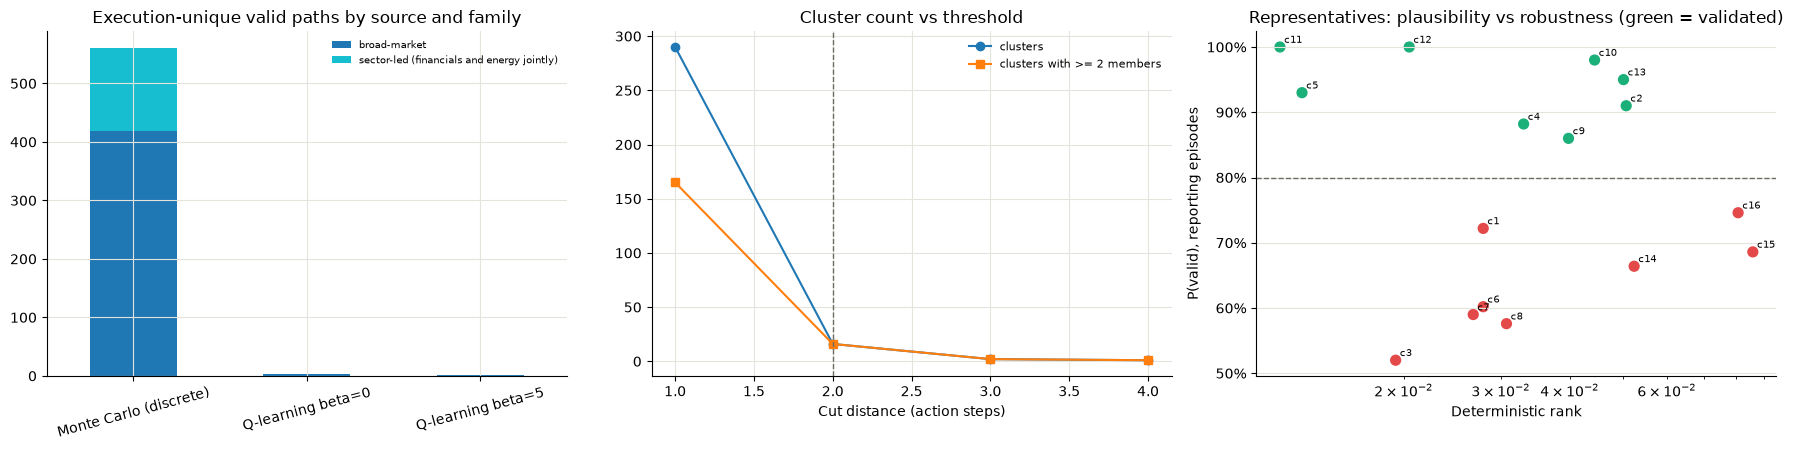

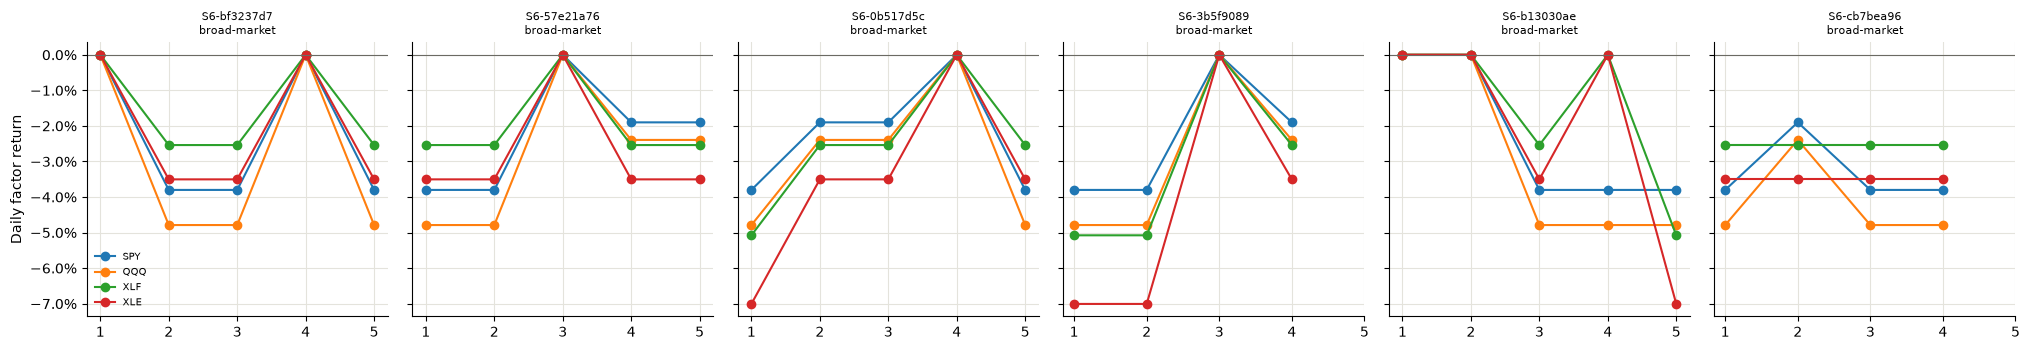

In [11]:
print(BANNER)
fig, axes = plt.subplots(1, 3, figsize=(18, 4.6))
if len(fam_by_method):
    fam_by_method.plot(kind="bar", stacked=True, ax=axes[0], colormap="tab10")
    axes[0].set_title("Execution-unique valid paths by source and family"); axes[0].set_xlabel(""); axes[0].tick_params(axis="x", rotation=15)
    axes[0].legend(frameon=False, fontsize=7)
axes[1].plot(sens["steps"], sens["clusters"], marker="o", label="clusters"); axes[1].plot(sens["steps"], sens["clusters with >= 2 members"], marker="s", label="clusters with >= 2 members")
axes[1].axvline(2, color="#6b6a63", linestyle="--", linewidth=1); axes[1].set_xlabel("Cut distance (action steps)"); axes[1].set_title("Cluster count vs threshold")
axes[1].legend(frameon=False, fontsize=8)
if len(rob):
    col = rob["status"].map({"validated": "#1baf7a", "exploratory": "#e34948"})
    axes[2].scatter(rob["rank"], rob["P(valid)"] * 100, c=col, s=50)
    for _, r in rob.iterrows():
        axes[2].annotate(f"c{r['cluster']}", (r["rank"], r["P(valid)"] * 100), fontsize=7, xytext=(3, 3), textcoords="offset points")
    axes[2].axhline(P_VALID_TARGET * 100, color="#6b6a63", linestyle="--", linewidth=1); axes[2].set_xscale("log")
    axes[2].set_xlabel("Deterministic rank"); axes[2].set_ylabel("P(valid), reporting episodes"); axes[2].yaxis.set_major_formatter(PercentFormatter())
    axes[2].set_title("Representatives: plausibility vs robustness (green = validated)")
plt.tight_layout(); plt.show()
val = [s for s in scenarios if s["status"] == "validated"][:6]
if val:
    fig, axes = plt.subplots(1, len(val), figsize=(3.4 * len(val), 3.6), sharey=True)
    for ax, s in zip(np.atleast_1d(axes), val):
        fs = np.array(s["factor_shock_path"]) * 100
        for j, n in enumerate(names):
            ax.plot(range(1, len(fs) + 1), fs[:, j], marker="o", label=n)
        ax.set_title(f"{s['scenario_id']}\n{s['family']}", fontsize=8); ax.set_xticks(range(1, H + 1)); ax.yaxis.set_major_formatter(PercentFormatter())
        ax.axhline(0, color="#6b6a63", linewidth=0.8)
    np.atleast_1d(axes)[0].legend(frameon=False, fontsize=7); np.atleast_1d(axes)[0].set_ylabel("Daily factor return")
    plt.tight_layout(); plt.show()

## 13. Assertions

In [12]:
checks = []
def check(name, ok, detail=""):
    checks.append({"check": name, "result": "PASS" if ok else "FAIL", "detail": detail})
check("factor order and path dimensions", tuple(model.factors) == FACTOR_ORDER and all(p.shape == (H, K) for p in candidate_paths.values()))
check("all candidate paths inside [-1, 1]", all(np.abs(p).max() <= 1.0 for p in candidate_paths.values()))
check("candidate IDs reproducible", all(candidate_id(r.source, candidate_paths[r.seq_key], r.seed) == r.candidate_id for r in cand.head(200).itertuples()))
check("valid <=> breached and rank >= q (existing rule)", ((cand["valid"]) == (cand["breached"] & (cand["rank"] >= Q_THRESHOLD))).all())
check("valid and implausible breaches disjoint", not (cand["valid"] & cand["implausible"]).any())
check("families and clusters use valid candidates only", bool(valid_exec["valid"].all()))
check("clustering deterministic", np.array_equal(cluster_features(X, CUTS["scenario cluster (2 steps)"]), valid_exec["cluster"].to_numpy()))
check("adaptive policies kept separate from fixed sequences", set(cand.loc[cand["source"].str.startswith("Q-learning"), "kind"]) <= {
      "deterministic greedy path", "adaptive trajectory replayed as fixed sequence"} and "policy" in adaptive.columns)
check("validated scenarios satisfy the declared rule", all(s["deterministic_rank"] >= Q_THRESHOLD and s["screening_p_valid"] >= P_VALID_TARGET
                                                        for s in scenarios if s["status"] == "validated"))
check("robustness path stored = path evaluated for robustness", all(np.array_equal(np.asarray(s["robust_action_path"]),
      candidate_paths[valid_exec.loc[valid_exec["candidate_id"] == s["representative_candidate_id"], "seq_key"].iloc[0]]) for s in scenarios))
check("scenario IDs unique", len({s["scenario_id"] for s in scenarios}) == len(scenarios))
check("evaluation anchors are validation dates; test split unused",
      eval_env.market_states.index.min() >= pd.Timestamp(splits["validation"][0]) and eval_env.market_states.index.max() <= pd.Timestamp(splits["validation"][1])
      and search_env.market_states.index.max() <= pd.Timestamp(splits["train"][1]) and train_env.market_states.index.max() <= pd.Timestamp(splits["train"][1]))
check("screening and reporting episodes disjoint", not set(SCREEN_SEEDS) & set(REPORT_SEEDS))
check("holding P&L sums to total P&L", all(abs(sum(v["holding_pnl"].values()) - v["total_pnl"]) < 1e-6 for v in vuln.values()))
check("Stage 4 reward and limits unchanged", ENVC.implausible_breach_penalty == 0.0 and ENVC.implausible_breach_credit == 0.0 and Q_THRESHOLD == 0.01)
if RUN_MODE == "full":
    mc_recs = mc["records"]
    check("Stage 5 reproduced (Monte Carlo original, Q-learning steps)",
          sum(r["breached"] for r in mc_recs) == STAGE5_RECORDED["mc_original_breaches"] and sum(r["valid"] for r in mc_recs) == STAGE5_RECORDED["mc_original_valid"]
          and runs[(0.0, Q_SEEDS[0])]["steps"] == STAGE5_RECORDED["q_beta0_seed43_steps"] and runs[(5.0, Q_SEEDS[0])]["steps"] == STAGE5_RECORDED["q_beta5_seed43_steps"])
checks_df = pd.DataFrame(checks)
display(checks_df.style.hide(axis="index").map(lambda v: "color: #008300; font-weight: bold" if v == "PASS" else ("color: #e34948; font-weight: bold" if v == "FAIL" else ""), subset=["result"]))
assert (checks_df["result"] == "PASS").all()
print(f"{len(checks_df)}/{len(checks_df)} checks PASS")

check,result,detail
factor order and path dimensions,PASS,
"all candidate paths inside [-1, 1]",PASS,
candidate IDs reproducible,PASS,
valid <=> breached and rank >= q (existing rule),PASS,
valid and implausible breaches disjoint,PASS,
families and clusters use valid candidates only,PASS,
clustering deterministic,PASS,
adaptive policies kept separate from fixed sequences,PASS,
validated scenarios satisfy the declared rule,PASS,
robustness path stored = path evaluated for robustness,PASS,


16/16 checks PASS


## 14. Limitations and use by Stage 7
**Limitations.** (1) The nine-action set ties SPY to QQQ and XLF to XLE, so technology-led, financial-only and energy-only scenarios are reachable only by the continuous Monte Carlo, which in Stage 5 found no valid path; absent families are a property of the search space, not evidence that such stresses are implausible. (2) Validation episodes differ only in residual draws (the anchor date does not change the dynamics), so robustness is to stock-specific noise, not to market regimes. (3) Stage 4 limitations carry over: i.i.d. daily shocks, tails about 15–16% lighter than history, plausibility calibrated on 2015–2021 windows dominated by March–April 2020, loss limit never decisive. (4) Family rules (δ) and cluster cuts are analyst choices; sensitivity is reported. (5) Factor attribution is model-implied, not causal.

**Stage 7.** `results/stage6/scenario_library.json` (schema `stage6.v1`): `scenarios[]` with `status`, `family`, the executed `action_path` and `factor_shock_path`, plausibility (`deterministic_rank`), reliability (`p_valid` with interval, `p_implausible`) and `vulnerability` (holding P&L, most vulnerable holdings, approximate factor P&L, portfolio loadings). A recommender should use **validated** scenarios for ranking and treat **exploratory** ones as context only; `metadata` records the rule, seeds, budgets and clustering choices needed to reproduce or re-weight them.